In [1]:
import math
import heapq
from collections import defaultdict

import networkx as nx
import numpy as np


# ---------- helpers ----------
def haversine(lat1, lon1, lat2, lon2):
    """Distance in metres between two lat/lon points."""
    R = 6371000
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi = p2 - p1
    dlmb = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlmb / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))


# ---------- step 0: make regions (skip if nodes already have a 'region') ----------
def assign_regions(G, n_regions=8):
    """Group nearby intersections into big regions using KMeans on coordinates.
    Needs: pip install scikit-learn"""
    from sklearn.cluster import KMeans
    nodes = list(G.nodes)
    coords = np.array([[G.nodes[n]["y"], G.nodes[n]["x"]] for n in nodes])
    labels = KMeans(n_clusters=n_regions, n_init=10, random_state=0).fit_predict(coords)
    for n, lab in zip(nodes, labels):
        G.nodes[n]["region"] = int(lab)


# ---------- step 1: build the small "region map" ----------
def build_region_graph(G, closed_edges=()):
    """closed_edges = set of (u, v) road segments that are blocked."""
    closed = set(closed_edges) | {(v, u) for u, v in closed_edges}

    members = defaultdict(list)
    for n, d in G.nodes(data=True):
        members[d["region"]].append(n)

    # centre point of each region
    centroid = {
        r: (np.mean([G.nodes[n]["y"] for n in ns]),
            np.mean([G.nodes[n]["x"] for n in ns]))
        for r, ns in members.items()
    }

    # two regions are neighbours if at least one open road joins them
    RG = nx.Graph()
    RG.add_nodes_from(members)
    for u, v in G.edges():
        if (u, v) in closed:
            continue
        ru, rv = G.nodes[u]["region"], G.nodes[v]["region"]
        if ru != rv and not RG.has_edge(ru, rv):
            RG.add_edge(ru, rv, cost=haversine(*centroid[ru], *centroid[rv]))
    return RG, centroid, members


# ---------- step 2: first-level A* over regions ----------
def first_level_search(G, start_node, goal_node, closed_edges=(), n_regions=8):
    if "region" not in G.nodes[start_node]:
        assign_regions(G, n_regions)

    RG, centroid, members = build_region_graph(G, closed_edges)
    start_r = G.nodes[start_node]["region"]
    goal_r = G.nodes[goal_node]["region"]
    goal_xy = (G.nodes[goal_node]["y"], G.nodes[goal_node]["x"])

    def h(r):  # straight-line distance to the goal
        return haversine(*centroid[r], *goal_xy)

    open_heap = [(h(start_r), 0, start_r)]
    came_from = {}
    best_g = {start_r: 0}

    while open_heap:
        _, g, r = heapq.heappop(open_heap)
        if r == goal_r:
            path = [r]
            while r in came_from:
                r = came_from[r]
                path.append(r)
            return path[::-1]          # ordered list of regions
        if g > best_g.get(r, float("inf")):
            continue
        for nb in RG.neighbors(r):
            ng = g + RG[r][nb]["cost"]
            if ng < best_g.get(nb, float("inf")):
                best_g[nb] = ng
                came_from[nb] = r
                heapq.heappush(open_heap, (ng + h(nb), ng, nb))
    return None                         # no route between regions


# ---------- example use ----------
# G = your road graph (networkx), nodes have 'x' (lon) and 'y' (lat)
# start = nearest node to Boxpark, goal = nearest node to Port de La Mer
# blocked = {(u1, v1), (u2, v2), ...}   # the magenta roads
#
# corridor = first_level_search(G, start, goal, closed_edges=blocked)
# print("Regions to pass through:", corridor)

Map loaded: 5169 intersections, 9964 road segments
Closed road segments: 18
Regions to pass through (no roadblock):   [1, 5]
Regions to pass through (with roadblock): [1, 5]


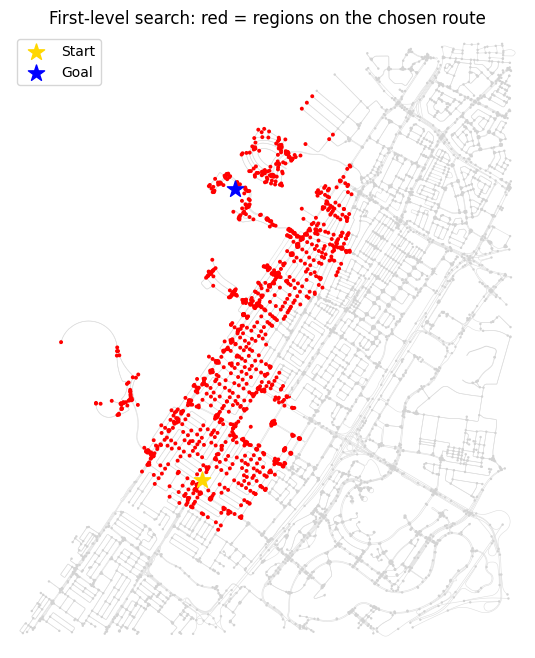

In [2]:
!pip install osmnx scikit-learn -q

import osmnx as ox
import matplotlib.pyplot as plt

# ---------- 1. load the Dubai road map ----------
def find_place(name, fallback):
    try:
        lat, lon = ox.geocode(name)
        return lat, lon
    except Exception:
        return fallback

# approximate fallback coordinates (lat, lon) if the name lookup fails
boxpark = find_place("Boxpark, Dubai", (25.2085, 55.2625))
port_de_la_mer = find_place("Port de La Mer, Dubai", (25.2345, 55.2610))
block_point = find_place("Jumeirah Beach Centre, Dubai", (25.2290, 55.2650))

center = ((boxpark[0] + port_de_la_mer[0]) / 2, (boxpark[1] + port_de_la_mer[1]) / 2)
G = ox.graph_from_point(center, dist=4500, network_type="drive")
print("Map loaded:", len(G.nodes), "intersections,", len(G.edges), "road segments")

start = ox.nearest_nodes(G, X=boxpark[1], Y=boxpark[0])
goal = ox.nearest_nodes(G, X=port_de_la_mer[1], Y=port_de_la_mer[0])

# ---------- 2. the roadblock (all roads within ~150 m of the block point) ----------
def near(n, point, metres=150):
    return haversine(G.nodes[n]["y"], G.nodes[n]["x"], point[0], point[1]) <= metres

blocked_nodes = {n for n in G.nodes if near(n, block_point)}
blocked = {(u, v) for u, v in G.edges() if u in blocked_nodes and v in blocked_nodes}
print("Closed road segments:", len(blocked))

# ---------- 3. run the first-level search ----------
assign_regions(G, n_regions=8)

path_before = first_level_search(G, start, goal, closed_edges=())
path_after = first_level_search(G, start, goal, closed_edges=blocked)

print("Regions to pass through (no roadblock):  ", path_before)
print("Regions to pass through (with roadblock):", path_after)

# ---------- 4. draw it ----------
regions_on_route = set(path_after or [])
node_colors = ["red" if G.nodes[n]["region"] in regions_on_route else "lightgray" for n in G.nodes]
node_sizes = [8 if G.nodes[n]["region"] in regions_on_route else 3 for n in G.nodes]

fig, ax = ox.plot_graph(G, node_color=node_colors, node_size=node_sizes,
                        edge_color="#dddddd", edge_linewidth=0.4,
                        bgcolor="white", show=False, close=False)
ax.scatter(G.nodes[start]["x"], G.nodes[start]["y"], c="gold", s=150, marker="*", zorder=5, label="Start")
ax.scatter(G.nodes[goal]["x"], G.nodes[goal]["y"], c="blue", s=150, marker="*", zorder=5, label="Goal")
ax.set_title("First-level search: red = regions on the chosen route")
ax.legend()
plt.show()

In [4]:
import networkx as nx

# ---------- 1. reload the map, keep only the connected main network ----------
G = ox.graph_from_point(center, dist=4500, network_type="drive")
G = ox.truncate.largest_component(G, strongly=True)
print("Map loaded:", len(G.nodes), "intersections,", len(G.edges), "road segments")

# ---------- 2. snap start and goal onto that connected network ----------
start = ox.nearest_nodes(G, X=boxpark[1], Y=boxpark[0])
goal = ox.nearest_nodes(G, X=port_de_la_mer[1], Y=port_de_la_mer[0])

# ---------- 3. rebuild the roadblock on the new map ----------
blocked_nodes = {n for n in G.nodes if near(n, block_point)}
blocked = {(u, v) for u, v in G.edges() if u in blocked_nodes and v in blocked_nodes}
print("Closed road segments:", len(blocked))

# ---------- 4. rebuild the regions on the new map ----------
assign_regions(G, n_regions=8)

# ---------- 5. check a route exists ----------
print("Route exists (no roadblock):  ", nx.has_path(G, start, goal))

H = G.copy()
H.remove_edges_from([(u, v, k) for u, v, k in G.edges(keys=True) if (u, v) in blocked or (v, u) in blocked])
print("Route exists (with roadblock):", nx.has_path(H, start, goal))

Map loaded: 4989 intersections, 9711 road segments
Closed road segments: 18
Route exists (no roadblock):   True
Route exists (with roadblock): True



=== No roadblock ===
Method              Distance (m)   Nodes expanded   Time (s)
Flat A*                     6549             1247      0.012
Two-tier A*                 6686              878      0.037   (chosen regions only)
Search effort saved: 29.6% fewer nodes
Extra distance vs best route: 137 m

=== With roadblock ===
Method              Distance (m)   Nodes expanded   Time (s)
Flat A*                     6549             1243      0.012
Two-tier A*                 6686              870      0.032   (chosen regions only)
Search effort saved: 30.0% fewer nodes
Extra distance vs best route: 137 m


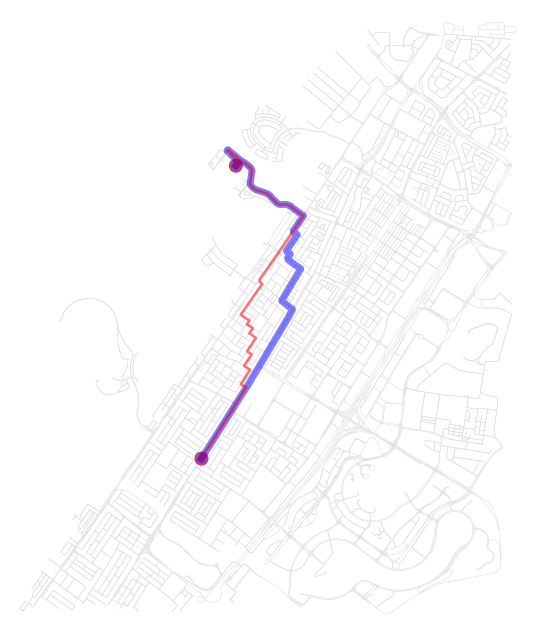

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [5]:
import time
import heapq
import osmnx as ox


# ---------- the search algorithm (A*) ----------
def astar(G, start, goal, allowed=None, closed=()):
    """A* on the road graph.
    allowed = set of nodes the search may use (None = whole map)
    closed  = blocked road segments (u, v)
    Returns: (route, distance_m, nodes_expanded) or (None, None, nodes_expanded)"""
    closed = set(closed) | {(v, u) for u, v in closed}
    gy, gx = G.nodes[goal]["y"], G.nodes[goal]["x"]

    def h(n):  # straight-line distance to the goal
        return haversine(G.nodes[n]["y"], G.nodes[n]["x"], gy, gx)

    open_heap = [(h(start), 0.0, start)]
    came_from, best_g, visited = {}, {start: 0.0}, set()
    expanded = 0

    while open_heap:
        _, g, n = heapq.heappop(open_heap)
        if n in visited:
            continue
        visited.add(n)
        expanded += 1

        if n == goal:
            route = [n]
            while n in came_from:
                n = came_from[n]
                route.append(n)
            return route[::-1], g, expanded

        for nb in G.successors(n):
            if allowed is not None and nb not in allowed:
                continue
            if (n, nb) in closed:
                continue
            edge_options = G.get_edge_data(n, nb).values()
            length = min(e.get("length", 1e9) for e in edge_options)
            ng = g + length
            if ng < best_g.get(nb, float("inf")):
                best_g[nb] = ng
                came_from[nb] = n
                heapq.heappush(open_heap, (ng + h(nb), ng, nb))
    return None, None, expanded


# ---------- two-tier search = first level + second level ----------
def two_tier_search(G, start, goal, closed=()):
    t0 = time.perf_counter()

    # Level 1: pick the regions to pass through
    regions = first_level_search(G, start, goal, closed_edges=closed)
    if regions is None:
        route, dist, exp = astar(G, start, goal, None, closed)   # fallback
        return route, dist, exp, time.perf_counter() - t0, "fallback: whole map"

    # Level 2: A* only on roads inside those regions
    allowed = {n for n in G.nodes if G.nodes[n]["region"] in regions}
    route, dist, exp = astar(G, start, goal, allowed, closed)
    note = "chosen regions only"

    # If the corridor was too narrow (e.g. roadblock), widen it to neighbouring regions
    if route is None:
        RG, _, _ = build_region_graph(G, closed)
        wider = set(regions)
        for r in regions:
            wider |= set(RG.neighbors(r))
        allowed = {n for n in G.nodes if G.nodes[n]["region"] in wider}
        route, dist, exp2 = astar(G, start, goal, allowed, closed)
        exp += exp2
        note = "widened to neighbouring regions"

    if route is None:
        route, dist, exp2 = astar(G, start, goal, None, closed)
        exp += exp2
        note = "fallback: whole map"

    return route, dist, exp, time.perf_counter() - t0, note


# ---------- run everything and compare ----------
results = {}
for label, closed in [("No roadblock", ()), ("With roadblock", blocked)]:
    t0 = time.perf_counter()
    f_route, f_dist, f_exp = astar(G, start, goal, None, closed)
    f_time = time.perf_counter() - t0

    t_route, t_dist, t_exp, t_time, note = two_tier_search(G, start, goal, closed)
    results[label] = (f_route, t_route)

    print(f"\n=== {label} ===")
    print(f"{'Method':<18}{'Distance (m)':>14}{'Nodes expanded':>17}{'Time (s)':>11}")
    print(f"{'Flat A*':<18}{f_dist:>14.0f}{f_exp:>17}{f_time:>11.3f}")
    print(f"{'Two-tier A*':<18}{t_dist:>14.0f}{t_exp:>17}{t_time:>11.3f}   ({note})")
    print(f"Search effort saved: {100 * (1 - t_exp / f_exp):.1f}% fewer nodes")
    print(f"Extra distance vs best route: {t_dist - f_dist:.0f} m")

# ---------- draw the routes with the roadblock ----------
flat_r, tier_r = results["With roadblock"]
ox.plot_graph_routes(G, [flat_r, tier_r], route_colors=["blue", "red"],
                     route_linewidths=[5, 2], node_size=0,
                     edge_color="#dddddd", edge_linewidth=0.4, bgcolor="white")